In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [26]:
from pathlib import Path

# Everything the report needs is written here: report/report.tex \inputs the tables and
# includes the figures, so both always show the numbers of the last run of this notebook.
TABLE_DIR = Path("report/tables")
FIGURE_DIR = Path("report/figures")
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

LATEX_HEADERS = {
    "Alpha": r"$\alpha$",
    "<E>": r"$\langle E \rangle$",
    "<V>": r"$\mathrm{var}(\langle E \rangle)$",
}


def export_table(df, name, alphas=None):
    """Save the full results frame as CSV and a LaTeX tabular for the report.

    The CSV keeps the whole alpha grid (that is what the plots use), while the table
    is restricted to `alphas` - the values Table 12.1 of the book reports.
    """
    df.to_csv(TABLE_DIR / f"{name}.csv", index=False)
    rows = df if alphas is None else df[df["Alpha"].round(3).isin(alphas)]
    rows.rename(columns=LATEX_HEADERS).to_latex(
        TABLE_DIR / f"{name}.tex",
        index=False,
        escape=False,
        column_format="ccc",
        formatters={r"$\alpha$": "${:.3f}$".format},
        float_format="${:.5f}$".format,  # math mode -> proper minus signs
    )


def export_figure(fig, name):
    r"""Save a figure as a PDF that report.tex picks up via \includegraphics{name}."""
    fig.savefig(FIGURE_DIR / f"{name}.pdf", bbox_inches="tight")


# General simulation

In [27]:
def vmc_simulation(N, alpha, walker_steps, equilibrium_steps, d, local_energy, psi_trial, initial_positions):
    shape = np.shape(initial_positions)
    walker_positions = initial_positions
    walker_energies_sum = np.zeros(N)
    walker_energies_squared_sum = np.zeros(N)

    for step in range(walker_steps):
        proposed_new_positions = walker_positions + np.random.uniform(-d / 2, +d / 2, shape)
        acceptance_ratio = (psi_trial(alpha, proposed_new_positions) / psi_trial(alpha, walker_positions)) ** 2
        will_move = np.random.random(N) < acceptance_ratio
        walker_positions[will_move] = proposed_new_positions[will_move]
        if step >= equilibrium_steps:
            e_l = local_energy(alpha, walker_positions)
            walker_energies_sum += e_l
            walker_energies_squared_sum += e_l ** 2

    e_l_expected = np.mean(walker_energies_sum / (walker_steps - equilibrium_steps))
    e_l_squared_expected = np.mean(walker_energies_squared_sum) / (walker_steps - equilibrium_steps)
    return e_l_expected, e_l_squared_expected - e_l_expected ** 2

# 1. Harmonic Oscillator

In [28]:
def psi_trial_ho(alpha, x):
    return np.exp(-alpha * x ** 2)


def local_energy_ho(alpha, x):
    return alpha + x ** 2 * (-2 * alpha ** 2 + 1 / 2)

alpha_values = np.arange(0.35,0.8, 0.025)
results = []
for alpha_trial in alpha_values:
    N = 400
    initial_positions = np.random.uniform(-1, 1, N)
    expected_energy, expected_variance = vmc_simulation(N=N, alpha=alpha_trial, walker_steps=30000,                 equilibrium_steps=4000, d=0.8, local_energy=local_energy_ho, psi_trial=psi_trial_ho, initial_positions=initial_positions)
    results.append({"Alpha": alpha_trial, "<E>": expected_energy, "<V>": expected_variance})

df_ho = pd.DataFrame(results)
# the book tabulates only these alpha values (Table 12.1)
export_table(df_ho, "harmonic_oscillator", alphas=[0.4, 0.45, 0.5, 0.55, 0.6])
df_ho

,Alpha,<E>,<V>
0,0.350,0.532098,0.066131
1,0.375,0.520754,0.042565
2,0.400,0.512783,0.025434
3,0.425,0.506399,0.013192
4,0.450,0.502821,0.005580
5,0.475,0.500631,0.001315
6,0.500,0.500000,0.000000
7,0.525,0.500560,0.001197
8,0.550,0.502093,0.004580
9,0.575,0.504786,0.009875


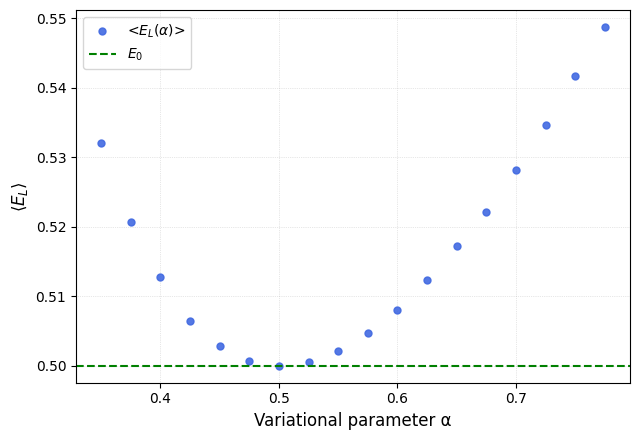

In [29]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.plot(
    df_ho["Alpha"], df_ho["<E>"],
    label='<$E_L(α)$>',
    color='royalblue',
    linestyle='none',
    marker='o',
    markersize=5,
    alpha=0.9
)

ax.set_xlabel("Variational parameter α", fontsize=12)
ax.set_ylabel(r"$\langle E_L \rangle$", fontsize=12)

ax.axhline(0.5, linestyle="--", color="green", label="$E_0$")

ax.legend(loc='best', frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
export_figure(fig, "harmonic_oscillator")
plt.show()

# 2. Hydrogen atom

Using Hamiltonian $H = -\frac{1}{2} \nabla^2 - \frac{1}{r}$

In [30]:
def psi_trial_h(alpha, x):
    r = np.linalg.norm(x, axis=1)
    return np.exp(-alpha * r)


def local_energy_h(alpha, x):
    r = np.linalg.norm(x, axis=1)
    return -1/r-1/2*alpha*(alpha-2/r)

alpha_values = np.arange(0.8, 1.25, 0.05)
results = []
for alpha_trial in alpha_values:
    N=400
    initial_positions = np.random.uniform(-1, 1, (N,3))
    expected_energy, expected_variance = vmc_simulation(N=400, alpha=alpha_trial, walker_steps=30000,
                                                        equilibrium_steps=4000, d=0.8, psi_trial=psi_trial_h, local_energy=local_energy_h, initial_positions=initial_positions)
    results.append({"Alpha": alpha_trial, "<E>": expected_energy, "<V>": expected_variance})

df_h = pd.DataFrame(results)
export_table(df_h, "hydrogen")
df_h

,Alpha,<E>,<V>
0,0.80,-0.480501,0.025716
1,0.85,-0.488323,0.015749
2,0.90,-0.495508,0.008211
3,0.95,-0.498660,0.002196
4,1.00,-0.500000,0.000000
5,1.05,-0.498657,0.002941
6,1.10,-0.495046,0.011738
7,1.15,-0.488703,0.028705
8,1.20,-0.479905,0.057873


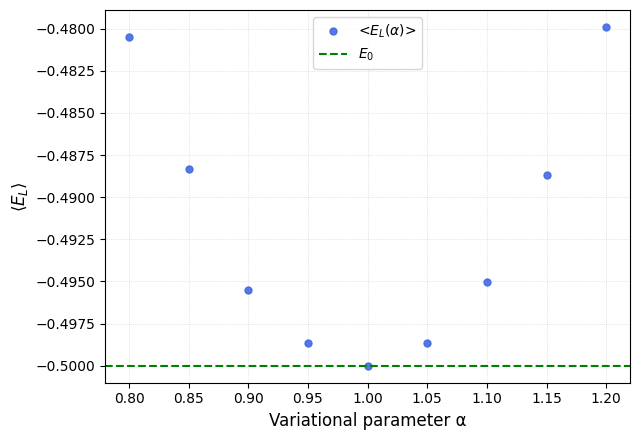

In [35]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))

ax.plot(
    df_h["Alpha"], df_h["<E>"],
    label='<$E_L(α)$>',
    color='royalblue',
    linestyle='none',
    marker='o',
    markersize=5,
    alpha=0.9
)

ax.set_xlabel("Variational parameter α", fontsize=12)
ax.set_ylabel(r"$\langle E_L \rangle$", fontsize=12)

ax.axhline(-0.5, linestyle="--", color="green", label="$E_0$")

ax.legend(loc='best', frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
export_figure(fig, "hydrogen")
plt.show()

#  3. Helium Atom

In [32]:
def psi_trial_he(alpha, positions):
    r_1 = positions[:,0,:]
    r_2 = positions[:,1,:]
    r_12_norm = np.linalg.norm(r_1-r_2, axis=1)
    return np.exp(-2*np.linalg.norm(r_1, axis=1)) * np.exp(-2*np.linalg.norm(r_2,axis=1)) * np.exp(r_12_norm/(2*(1+alpha*r_12_norm)))

def local_energy_he(alpha, positions):
    r_1 = positions[:,0,:]
    r_2 = positions[:,1,:]
    r_12_norm = np.linalg.norm(r_1-r_2, axis=1)
    return -4+np.sum((r_1/np.linalg.norm(r_1, axis=1, keepdims=True) - r_2/np.linalg.norm(r_2,axis=1, keepdims=True)) * (r_1-r_2), axis=1) * 1/(r_12_norm *(1+alpha*r_12_norm)**2)-1/(r_12_norm*(1+alpha*r_12_norm)**3)-1/(4*(1+alpha*r_12_norm)**4) + 1/r_12_norm


alpha_values = [0.05, 0.075, 0.10, 0.125, 0.15, 0.175, 0.20, 0.25]
results = []
for alpha_trial in alpha_values:
    N = 400
    initial_positions = np.random.uniform(-0.5, 0.5, (N,2,3))
    expected_energy, expected_variance = vmc_simulation(N=N, alpha=alpha_trial, walker_steps=30000,
                                                        equilibrium_steps=10000, d=1, local_energy=local_energy_he, psi_trial=psi_trial_he, initial_positions=initial_positions)
    results.append({"Alpha": alpha_trial, "<E>": expected_energy, "<V>": expected_variance})

df_he = pd.DataFrame(results)
export_table(df_he, "helium")
df_he

,Alpha,<E>,<V>
0,0.050,-2.870744,0.175669
1,0.075,-2.875136,0.153677
2,0.100,-2.877059,0.136336
3,0.125,-2.877816,0.122412
4,0.150,-2.878198,0.112022
5,0.175,-2.878036,0.103395
6,0.200,-2.877163,0.096838
7,0.250,-2.873966,0.088651


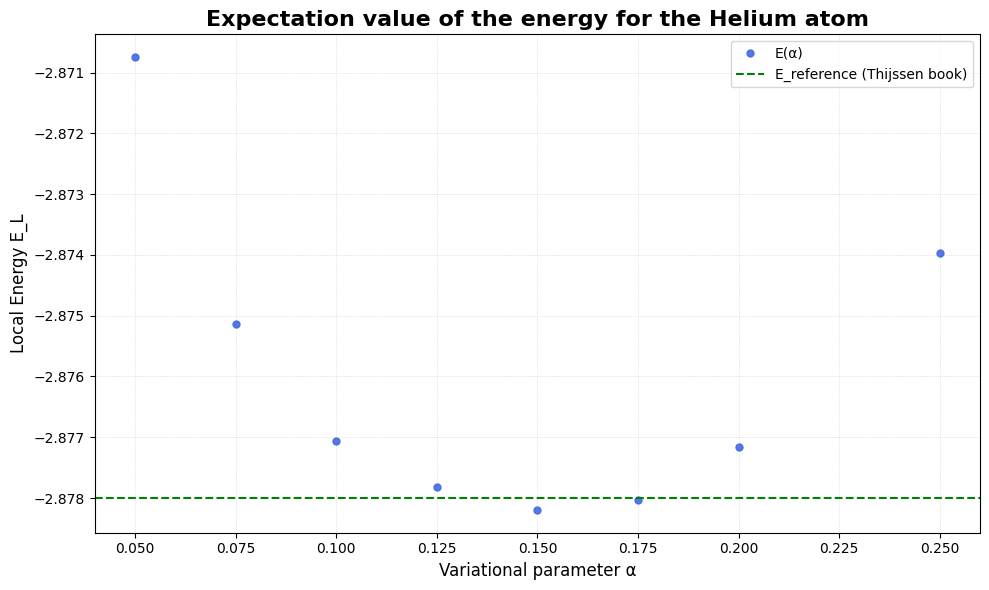

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    df_he["Alpha"], df_he["<E>"],
    label='E(α)',      # Label for the legend
    color='royalblue',        # Hex code or named color
    linestyle='none',           # Options: '-', '--', '-.', ':'              # Thickness of the line
    marker='o',               # Marker style (optional)
    markersize=5,                 # Size of the marker
    alpha=0.9                 # Opacity (0.0 to 1.0)
)

ax.set_title("Expectation value of the energy for the Helium atom", fontsize=16, fontweight='bold')
ax.set_xlabel("Variational parameter α", fontsize=12)
ax.set_ylabel("Local Energy E_L", fontsize=12)

ax.axhline(-2.878, linestyle="--", color="green", label="E_reference (Thijssen book)")

ax.legend(loc='best', frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Performance profiling

In [34]:
import line_profiler

lp = line_profiler.LineProfiler(vmc_simulation)
lp.runcall(vmc_simulation, N=400, alpha=0.125, walker_steps=30000,
           equilibrium_steps=4000, d=1, local_energy=local_energy_he, psi_trial=psi_trial_he, initial_positions=np.random.uniform(-0.5,0.5,(400,2,3)))
lp.print_stats()

ModuleNotFoundError: No module named 'line_profiler'